In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.preprocessing import LabelEncoder

# Home Credit Default Risk – Data Analysis

**Objective:** Explore the Home Credit loan data to understand which client characteristics are associated with loan default (repayment difficulties), as a foundation for credit risk assessment.

**Data source:** [Home Credit Default Risk – Kaggle Competition](https://www.kaggle.com/competitions/home-credit-default-risk)

Home Credit provides consumer loans to people with little or no credit history. The dataset contains loan applications and related credit history. Files used in this notebook:

| File | Description |
|---|---|
| `application_train.csv` | Main table: one row per loan application (`SK_ID_CURR`), with client demographics, income, loan details and the target variable `TARGET` (1 = client had payment difficulties, 0 = repaid on time) |
| `bureau.csv` | Client's previous credits from other financial institutions reported to the Credit Bureau, linked to the main table via `SK_ID_CURR` |

**Notebook structure:** read data → check missing values → exploratory analysis of default drivers.

# 1. Read Data and Exploration data

## 1.1 Read data

In [2]:
application_train = pd.read_csv('/kaggle/input/home-credit-default-risk/application_train.csv')
bureau_credit = pd.read_csv('/kaggle/input/home-credit-default-risk/bureau.csv')

## 1.1 Check misssing values

In [3]:
def missing_values_table(df):
        # Total missing values
        mis_val = df.isnull().sum()
        
        # Percentage of missing values
        mis_val_percent = 100 * df.isnull().sum() / len(df)
        
        # Make a table with the results
        mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)
        
        # Rename the columns
        mis_val_table_ren_columns = mis_val_table.rename(
        columns = {0 : 'Missing Values', 1 : '% of Total Values'})
        
        # Sort the table by percentage of missing descending
        mis_val_table_ren_columns = mis_val_table_ren_columns[
            mis_val_table_ren_columns.iloc[:,1] != 0].sort_values(
        '% of Total Values', ascending=False).round(1)
        
        # Print some summary information
        print ("Your selected dataframe has " + str(df.shape[1]) + " columns.\n"      
            "There are " + str(mis_val_table_ren_columns.shape[0]) +
              " columns that have missing values.")
        
        # Return the dataframe with missing information
        return mis_val_table_ren_columns

In [4]:
# Missing values statistics
missing_values = missing_values_table(application_train)
missing_values = missing_values.reset_index()
missing_values.rename(columns={'index': 'Column Name'}, inplace=True)
print('The first 10 columns having the largest missing value ratio:')
missing_values.head(10)

Your selected dataframe has 122 columns.
There are 67 columns that have missing values.
The first 10 columns having the largest missing value ratio:


,Column Name,Missing Values,% of Total Values
0,COMMONAREA_MEDI,214865,69.9
1,COMMONAREA_AVG,214865,69.9
2,COMMONAREA_MODE,214865,69.9
3,NONLIVINGAPARTMENTS_MEDI,213514,69.4
4,NONLIVINGAPARTMENTS_MODE,213514,69.4
5,NONLIVINGAPARTMENTS_AVG,213514,69.4
6,FONDKAPREMONT_MODE,210295,68.4
7,LIVINGAPARTMENTS_MODE,210199,68.4
8,LIVINGAPARTMENTS_MEDI,210199,68.4
9,LIVINGAPARTMENTS_AVG,210199,68.4


Common Missing Value Thresholds:
- Less than 5% missing → Usually safe to fill (impute) the missing values.
- 5% to 30% missing → Consider imputing or dropping, depending on importance.
- More than 30-50% missing → Drop if the column is not critical or has low correlation.
- More than 70-80% missing → Usually a strong candidate for dropping unless very important.

--> Drop missing values columns having > 70% missing columns

In [5]:
missing_threshold = 70
column_to_drop = missing_values[missing_values["% of Total Values"] > missing_threshold]["Column Name"]

df_train = application_train.drop(columns=column_to_drop)  # Drop second column

# Missing values statistics
missing_values = missing_values_table(df_train)
missing_values = missing_values.reset_index()
missing_values.rename(columns={'index': 'Column Name'}, inplace=True)
missing_values.head(20)

Your selected dataframe has 122 columns.
There are 67 columns that have missing values.


,Column Name,Missing Values,% of Total Values
0,COMMONAREA_MEDI,214865,69.9
1,COMMONAREA_AVG,214865,69.9
2,COMMONAREA_MODE,214865,69.9
3,NONLIVINGAPARTMENTS_MEDI,213514,69.4
4,NONLIVINGAPARTMENTS_MODE,213514,69.4
5,NONLIVINGAPARTMENTS_AVG,213514,69.4
6,FONDKAPREMONT_MODE,210295,68.4
7,LIVINGAPARTMENTS_MODE,210199,68.4
8,LIVINGAPARTMENTS_MEDI,210199,68.4
9,LIVINGAPARTMENTS_AVG,210199,68.4


The proportion of default customers (Target = 1) in customers having missing values in each feature:


In [6]:
missing_values_PD_rate =[]

for i in missing_values["Column Name"]:
    #print(i)
    df_missing_rows = df_train[df_train[['TARGET', i]].isnull().any(axis=1)][['TARGET', i]]
    df_missing_rows_PD = df_missing_rows[df_missing_rows['TARGET'] == 1 ]
    df_missing_rows_NonPD = df_missing_rows[df_missing_rows['TARGET'] == 0 ]

    x1 = df_missing_rows_PD.shape[0]
    x2 = df_missing_rows_NonPD.shape[0]
    PD_rate = x1/(x1+x2)
    missing_values_PD_rate.append(PD_rate)
missing_values['PD_rate'] = missing_values_PD_rate

#comparision with PD rate of full portfolio
df_train_PD = df_train[df_train['TARGET'] == 1 ]
df_train_NonPD = df_train[df_train['TARGET'] == 0 ]

x11 = df_train_PD.shape[0]
x22 = df_train_NonPD.shape[0]
missing_values['PD_rate_total'] = x11/(x11+x22)

missing_values

,Column Name,Missing Values,% of Total Values,PD_rate,PD_rate_total
0,COMMONAREA_MEDI,214865,69.9,0.085742,0.080729
1,COMMONAREA_AVG,214865,69.9,0.085742,0.080729
2,COMMONAREA_MODE,214865,69.9,0.085742,0.080729
3,NONLIVINGAPARTMENTS_MEDI,213514,69.4,0.085835,0.080729
4,NONLIVINGAPARTMENTS_MODE,213514,69.4,0.085835,0.080729
...,...,...,...,...,...
62,EXT_SOURCE_2,660,0.2,0.078788,0.080729
63,AMT_GOODS_PRICE,278,0.1,0.075540,0.080729
64,AMT_ANNUITY,12,0.0,0.000000,0.080729
65,CNT_FAM_MEMBERS,2,0.0,0.000000,0.080729


For missing data exceeding 50%, the PD rate is observed to be consistently higher (by 0.5% to 1%) compared to the PD rate of the entire customer base. The columns with missing values all pertain to information about housing and the loan's residential area. However, in practice, this information is difficult to collect, and since the PD rate is not excessively high, the missing data can be considered acceptable

In [7]:
missing_values[(missing_values['PD_rate'] > missing_values['PD_rate_total']) & (missing_values['% of Total Values'] >= 50)].head(10)

,Column Name,Missing Values,% of Total Values,PD_rate,PD_rate_total
0,COMMONAREA_MEDI,214865,69.9,0.085742,0.080729
1,COMMONAREA_AVG,214865,69.9,0.085742,0.080729
2,COMMONAREA_MODE,214865,69.9,0.085742,0.080729
3,NONLIVINGAPARTMENTS_MEDI,213514,69.4,0.085835,0.080729
4,NONLIVINGAPARTMENTS_MODE,213514,69.4,0.085835,0.080729
5,NONLIVINGAPARTMENTS_AVG,213514,69.4,0.085835,0.080729
6,FONDKAPREMONT_MODE,210295,68.4,0.086188,0.080729
7,LIVINGAPARTMENTS_MODE,210199,68.4,0.086214,0.080729
8,LIVINGAPARTMENTS_MEDI,210199,68.4,0.086214,0.080729
9,LIVINGAPARTMENTS_AVG,210199,68.4,0.086214,0.080729


## 1.2 Identify numerical and categorical features

In [8]:
numerical_columns = df_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_columns = df_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print(f'Numbers of columns are {df_train.shape[1]}')
print(f'umbers of numerical columns are  = {len(numerical_columns)}')
print(f'umbers of categorical columns are  = {len(categorical_columns)}')

Numbers of columns are 122
umbers of numerical columns are  = 106
umbers of categorical columns are  = 16


# 2. Exploratory Data Analysis (EDA)

In [9]:
def df_grouped(dataframe, selected_column):
    def format_as_percentage(s: float) -> str:
        return f"{round(s*100, 2)}%"
    df_grouped = dataframe.groupby(selected_column, as_index=False).agg(
    Customer_Count=('SK_ID_CURR', 'count'),  
    Total_Loan_Amount=('AMT_CREDIT', 'sum'),  
    Ticket_size=('AMT_CREDIT', 'mean'),
    Default_Count=('TARGET', lambda x: (x == 1).sum()),  # Số lượng khách hàng bị vỡ nợ (PD = 1)
    Non_Default_Count=('TARGET', lambda x: (x == 0).sum())  # Số KH không vỡ nợ
    )

    # PD rate
    df_grouped['PD_Rate'] = df_grouped['Default_Count'] / (df_grouped['Default_Count'] + df_grouped['Non_Default_Count'])
    df_grouped = df_grouped.sort_values(by='PD_Rate')
    
    # proportion
    df_grouped['Customer_Percentage'] = df_grouped['Customer_Count'] / df_grouped['Customer_Count'].sum()
    df_grouped['Loan_Percentage'] = df_grouped['Total_Loan_Amount'] / df_grouped['Total_Loan_Amount'].sum()
    
    # rounding
    df_grouped['Total_Loan_Amount'] = df_grouped['Total_Loan_Amount']/(10**6)
    df_grouped['Ticket_size'] = df_grouped['Ticket_size']/(10**6)
    df_grouped['PD_Rate'] = df_grouped['PD_Rate'].map(format_as_percentage)
    df_grouped['Customer_Percentage'] = df_grouped['Customer_Percentage'].map(format_as_percentage)
    df_grouped['Loan_Percentage'] = df_grouped['Loan_Percentage'].map(format_as_percentage)
    
    return df_grouped[[selected_column, 'Customer_Count', 'Customer_Percentage', 'Total_Loan_Amount', 'Loan_Percentage', 'Ticket_size', 'PD_Rate']]

In [10]:
def plot_numerical_features( dataframe ,selected_column, bins, xlabel_rotation: int = 0):
    plt.figure(figsize=(8, 5))
    sns.histplot(dataframe[dataframe['TARGET'] == 0]['selected_column'], bins=bins, color='blue', label='Target 0', kde=True, alpha=0.6)
    sns.histplot(dataframe[dataframe['TARGET'] == 1]['selected_column'], bins=bins, color='red', label='Target 1', kde=True, alpha=0.6)
    
    
    plt.title(f"Feature Distribution by {selected_column}")
    plt.xlabel(selected_column)
    plt.ylabel("Count contracts")
    plt.xticks(rotation=xlabel_rotation)
    plt.legend()
    plt.show()

In [11]:
def plot_categorical_features(dataframe, selected_column, sum_value, formula: str, xlabel_rotation: int = 0):
    
    if formula == 'count':
        agg_data = dataframe[selected_column].value_counts(normalize=True) 
    elif formula == 'sum':
        agg_data = dataframe.groupby(selected_column)[sum_value].sum()
        agg_data = sum_table / sum_table.sum()  # Normalize
    else:
        raise Exception("Invalid formula")
    agg_data = agg_data.sort_index(ascending=True)
    #PD rate
    pd_per_category = dataframe.groupby(selected_column)['TARGET'].mean()  # PD (Target=1 proportion per category)
    pd_per_category = pd_per_category.sort_index(ascending=True)
    #plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    #Proportion
    #formula.plot(x=selected_column, kind='bar', stacked=True)
    sns.barplot(x=agg_data.index, y=agg_data.values*100, ax=axes[0], palette="coolwarm")
    axes[0].set_title(f"Proportion of {selected_column}")
    axes[0].set_xlabel(selected_column)
    axes[0].set_ylabel("Proportion")
    axes[0].tick_params(axis='x', labelrotation=xlabel_rotation)

    for i, v in enumerate(agg_data.values):
        axes[0].text(i, v + 0.01, f"{v:.2%}", ha='center', fontsize=10)

    
    #PD rate
    sns.barplot(x=pd_per_category.index, y=pd_per_category.values*100, ax=axes[1], palette="coolwarm")
    axes[1].set_title(f"PD rate by {selected_column}")
    axes[1].set_xlabel(selected_column)
    axes[1].set_ylabel("Proportion")
    axes[1].tick_params(axis='x', labelrotation=xlabel_rotation)

    for i, v in enumerate(pd_per_category.values):
        axes[1].text(i, v + (pd_per_category.max() * 0.01), f"{v:.2%}", ha='center', fontsize=10)
    
    plt.tight_layout()
    plt.show()

## 2.1 High Disbursement of Cash Loans, Yet High PD Rate

Cash loans are mostly disbursed and have a ticket size nearly twice as large as revolving loans; however, the PD rate is higher at 8.35% compared to 5.48%.

Summary information of NAME_CONTRACT_TYPE


,NAME_CONTRACT_TYPE,Customer_Count,Customer_Percentage,Total_Loan_Amount,Loan_Percentage,Ticket_size,PD_Rate
1,Revolving loans,29279,9.52%,9486.922500,5.15%,0.324018,5.48%
0,Cash loans,278232,90.48%,174720.161695,94.85%,0.627966,8.35%


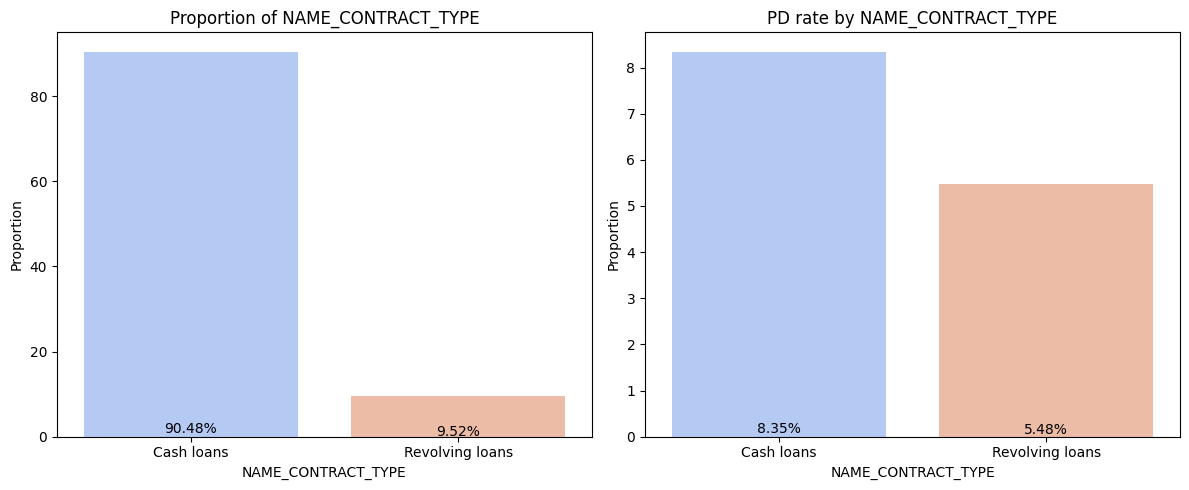

In [12]:
selected_column = 'NAME_CONTRACT_TYPE'

print(f'Summary information of {selected_column}')

display(df_grouped(df_train, selected_column))

if selected_column in numerical_columns:
    plot_numerical_features(df_train,selected_column, 20)
else:
    formula = 'count'
    plot_categorical_features(df_train, selected_column, 'AMT_CREDIT', formula)

## 2.2 Younger Age, Higher Risk of Bad Debt

- Debt quality or PD rate shows a clear distinction by age. Specifically, younger customers have a higher likelihood of defaulting. For the Home Credit portfolio, 14.63% of loans were issued to customers aged 25-30; however, their PD rate reached 11.46%, which is higher than the average PD rate of 8.07%.

- Home Credit lends to customers with a minimum age of 25, who may have only recently graduated from university and have limited work experience. Their income might be unstable, affecting their ability to repay loans. Home Credit does not provide loans to students.

## 2.3 Lower Education Level, Higher PD Risk

Summary information of AGE_GROUP


,AGE_GROUP,Customer_Count,Customer_Percentage,Total_Loan_Amount,Loan_Percentage,Ticket_size,PD_Rate
4,60+,35595,11.58%,18705.117721,10.15%,0.525498,4.92%
3,50-60,68074,22.14%,44037.384979,23.91%,0.646905,6.13%
2,40-50,76543,24.89%,50349.734212,27.33%,0.657797,7.66%
1,30-40,82299,26.76%,49429.586767,26.83%,0.600610,9.58%
0,25-30,45000,14.63%,21685.260515,11.77%,0.481895,11.46%


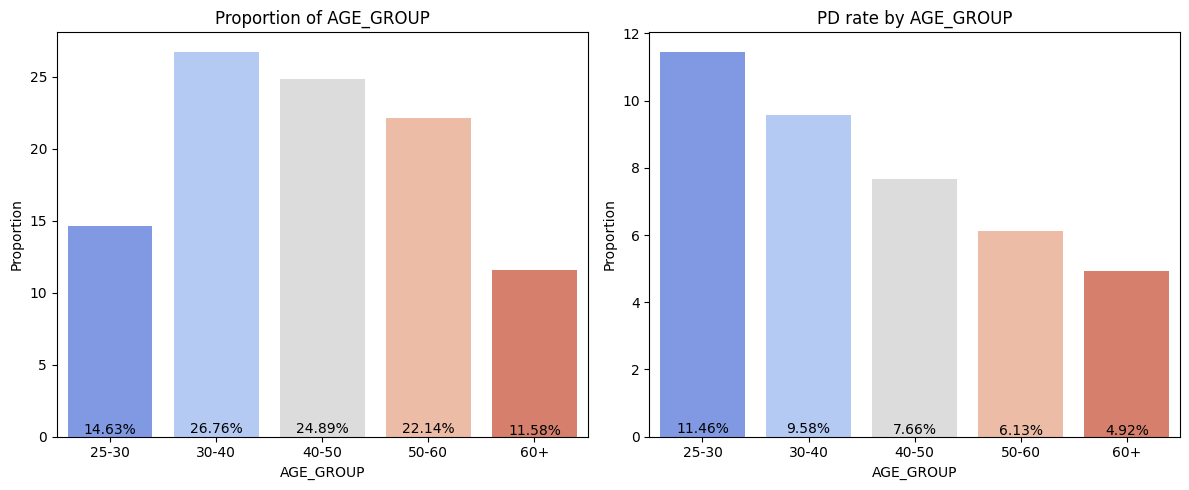

In [13]:
df_train['AGE_BIRTH'] = df_train['DAYS_BIRTH'] * (-1) / 365
df_train['AGE_BIRTH'] = df_train['AGE_BIRTH'].astype(int)
df_train['AGE_GROUP'] = np.where(df_train['AGE_BIRTH'] < 20, '<25',
                         np.where(df_train['AGE_BIRTH'] < 30, '25-30', 
                         np.where(df_train['AGE_BIRTH'] < 40, '30-40',
                         np.where(df_train['AGE_BIRTH'] < 50, '40-50', 
                         np.where(df_train['AGE_BIRTH'] < 60, '50-60', '60+')))))

categorical_columns.append('AGE_GROUP')

#display
selected_column = 'AGE_GROUP'
print(f'Summary information of {selected_column}')

display(df_grouped(df_train, selected_column))

if selected_column in numerical_columns:
    plot_numerical_features(df_train,selected_column, 20)
else:
    formula = 'count'
    plot_categorical_features(df_train, selected_column, 'AMT_CREDIT', formula)

- Debt quality or PD rate shows a clear distinction by education level.
- Loan contracts are predominantly held by customers with a secondary/secondary special education level, accounting for 71.02% of total loans. The PD rate for this group is higher than the overall portfolio PD rate.
- For customers with a lower secondary education level, although disbursements account for only 1.24%, their PD rate reaches 10.93%.

Summary information of NAME_EDUCATION_TYPE


,NAME_EDUCATION_TYPE,Customer_Count,Customer_Percentage,Total_Loan_Amount,Loan_Percentage,Ticket_size,PD_Rate
0,Academic degree,164,0.05%,118.656563,0.06%,0.723516,1.83%
1,Higher education,74863,24.34%,51651.760995,28.04%,0.689950,5.36%
2,Incomplete higher,10277,3.34%,5824.289956,3.16%,0.566731,8.48%
4,Secondary / secondary special,218391,71.02%,124743.496171,67.72%,0.571193,8.94%
3,Lower secondary,3816,1.24%,1868.880510,1.01%,0.489749,10.93%


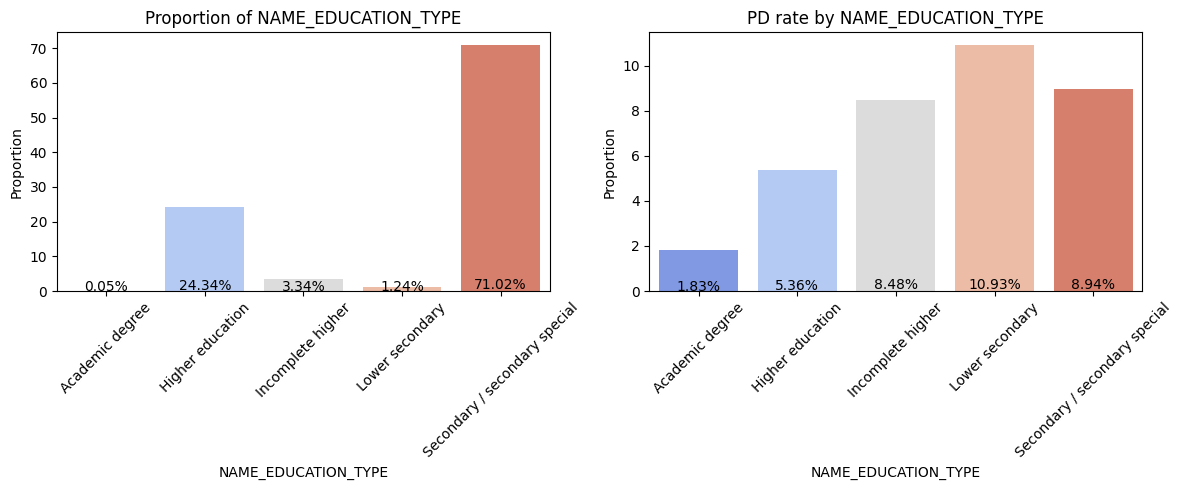

In [14]:
selected_column = 'NAME_EDUCATION_TYPE'
sum_column = "AMT_CREDIT"

#display

print(f'Summary information of {selected_column}')

display(df_grouped(df_train, selected_column))

if selected_column in numerical_columns:
    plot_numerical_features(df_train,selected_column, 20, 45)
else:
    formula = 'count'
    plot_categorical_features(df_train, selected_column, sum_column, formula, 45)

## 2.4 Lower-Skill Jobs, Higher PD Rates

Customer occupations are clustered into three major groups based on skill requirements:
(1) Low-Skill & Manual Jobs
(2) Mid-Skill & Office Support Jobs
(3) High-Skill & Professional Jobs

Debt quality or PD rate shows a clear distinction by skill requirement.
Occupations requiring low skills have the highest PD rate, reaching 10.84%, while the PD rate gradually decreases for the mid-skill and high-skill groups.

In [15]:
df_train['OCCUPATION_TYPE'].unique()

array(['Laborers', 'Core staff', 'Accountants', 'Managers', nan,
       'Drivers', 'Sales staff', 'Cleaning staff', 'Cooking staff',
       'Private service staff', 'Medicine staff', 'Security staff',
       'High skill tech staff', 'Waiters/barmen staff',
       'Low-skill Laborers', 'Realty agents', 'Secretaries', 'IT staff',
       'HR staff'], dtype=object)

Summary information of OCCUPATION_TYPE_GROUP


,OCCUPATION_TYPE_GROUP,Customer_Count,Customer_Percentage,Total_Loan_Amount,Loan_Percentage,Ticket_size,PD_Rate
0,High-Skill & Professional Jobs,51627,16.79%,36371.931147,19.75%,0.704514,6.02%
3,N/A,96391,31.35%,55360.217254,30.05%,0.574330,6.51%
2,Mid-Skill & Office Support Jobs,64943,21.12%,38643.949791,20.98%,0.595044,7.99%
1,Low-Skill & Manual Jobs,94550,30.75%,53830.986003,29.22%,0.569339,10.84%


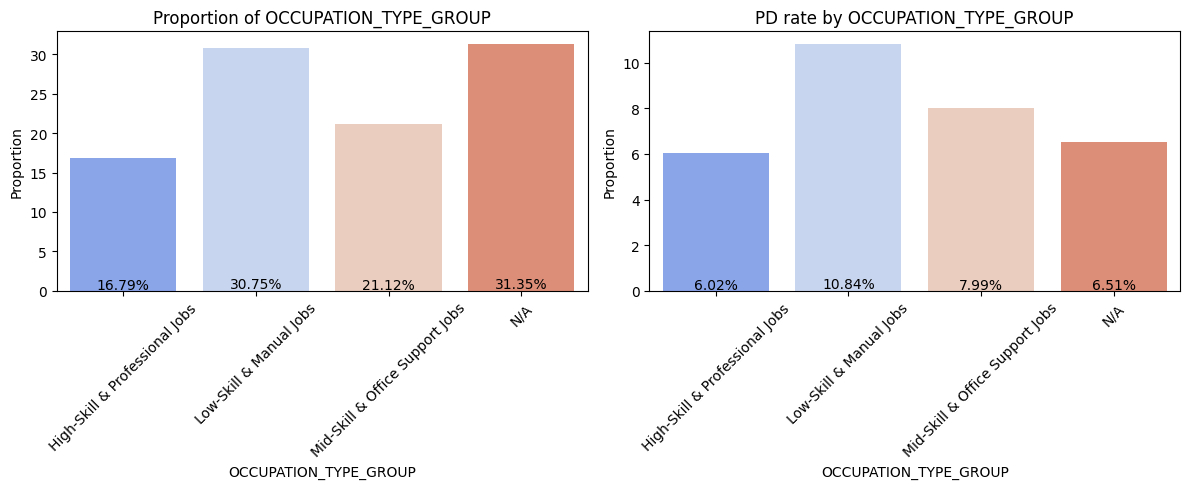

In [16]:
def occupation_by_level(job: str):
    if job in ["Laborers", "Low-skill Laborers", "Drivers", "Cleaning staff", "Cooking staff", "Waiters/barmen staff", "Security staff"]:
        return 'Low-Skill & Manual Jobs'
    elif job in ["Core staff", "Sales staff", "Private service staff", "Secretaries", "HR staff", "Realty agents"]:
        return 'Mid-Skill & Office Support Jobs'
    elif job in ["Accountants", "Managers", "Medicine staff", "High skill tech staff", "IT staff"]: 
        return 'High-Skill & Professional Jobs'
    else:
        return 'N/A'

df_train['OCCUPATION_TYPE_GROUP'] = df_train['OCCUPATION_TYPE'].map(occupation_by_level)
selected_column = 'OCCUPATION_TYPE_GROUP'
sum_column = "AMT_CREDIT"

categorical_columns.append('OCCUPATION_TYPE_GROUP')

#display
print(f'Summary information of {selected_column}')

display(df_grouped(df_train, selected_column))

if selected_column in numerical_columns:
    plot_numerical_features(df_train,selected_column, 20, 45)
else:
    formula = 'count'
    plot_categorical_features(df_train, selected_column, sum_column, formula, 45)

## 2.5 An In-Depth Analysis of Customer Occupations

### 2.5.1 Customer demographic information 

- The distribution of regional ratings across customer groups by occupation shows no significant differences. Rating type 2 dominates, accounting for over 70% in each occupational group.
- However, customers living in regions with higher ratings tend to have a lower default rate.

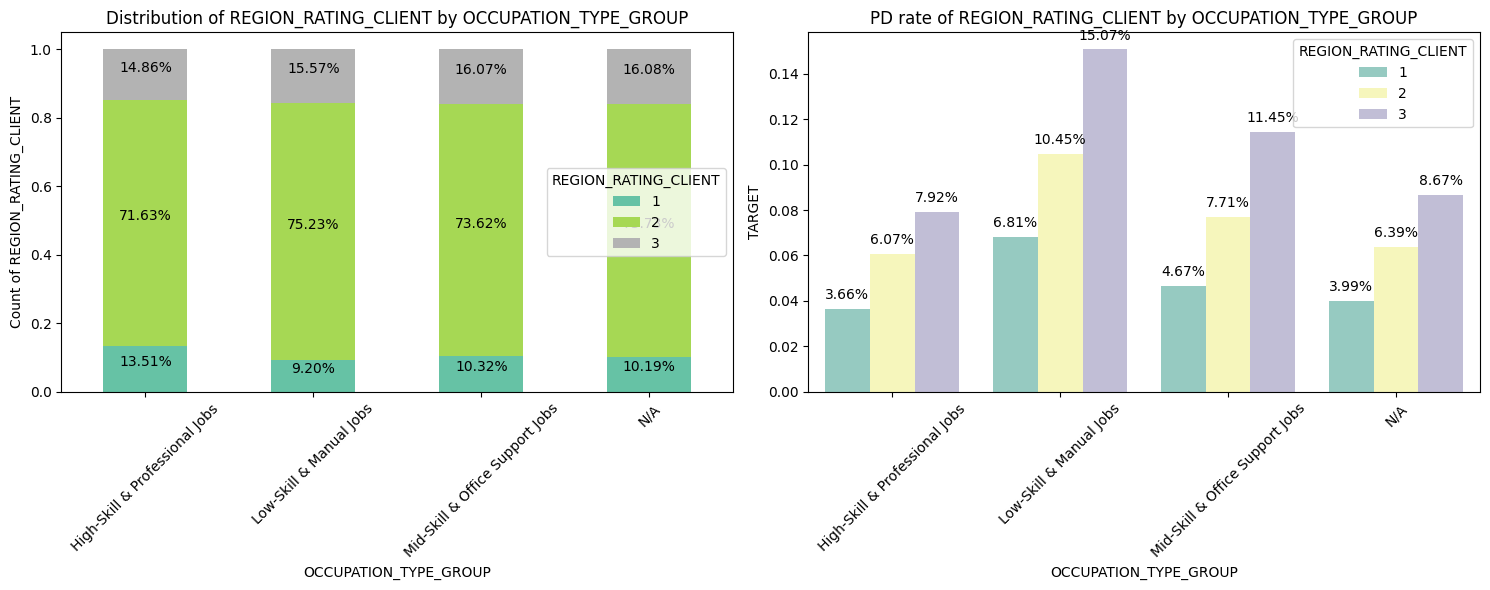

In [17]:

subset = ['OCCUPATION_TYPE_GROUP', 'REGION_RATING_CLIENT']
formula = 'Count'
xlabel_rotation = 45

#proportion
df_grouped = df_train.groupby(subset).size().reset_index(name=formula)
    
total_count_per_A = df_grouped.groupby(subset[0])[formula].transform('sum')
df_grouped['Proportion'] = df_grouped[formula] / total_count_per_A

df_pivot_proportion = df_grouped.pivot_table(index=subset[0], columns=subset[1], values='Proportion', aggfunc='sum', fill_value=0)

#PD rate
pd_per_category = df_train.groupby(subset)['TARGET'].mean().reset_index()

#plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

#sns.barplot(x=subset[0], y='Proportion', hue=subset[1], data=df_grouped, palette='Set2', ax=axes[0])
ax0 = df_pivot_proportion.plot(kind='bar', stacked=True, ax=axes[0], cmap='Set2')

for p in ax0.patches:
    height = p.get_height()
    if height > 0: 
        ax0.annotate(f'{height:.2%}', 
                     (p.get_x() + p.get_width() / 2., p.get_y() + p.get_height() / 2.), 
                     xytext=(0, 5), 
                     textcoords='offset points', 
                     ha='center', va='center')
    
axes[0].set_title(f'Distribution of {subset[1]} by {subset[0]}')
axes[0].set_xlabel(subset[0])
axes[0].set_ylabel(f'{formula} of {subset[1]}')
axes[0].tick_params(axis='x', labelrotation=xlabel_rotation)

sns.barplot(x=subset[0], y='TARGET', hue=subset[1], data=pd_per_category, palette='Set3', ax=axes[1])

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2%}', 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     xytext=(0, 5), 
                     textcoords='offset points', 
                     ha='center', va='bottom')
    
axes[1].set_title(f'PD rate of {subset[1]} by {subset[0]}')
axes[1].set_xlabel(subset[0])
axes[1].tick_params(axis='x', labelrotation=xlabel_rotation)

plt.tight_layout()
plt.show()

- Occupations requiring higher skills tend to have a higher proportion of customers with higher education. However, Home Credit's customer base is largely concentrated in the Secondary/Secondary Special group, making up 50% - 80% of each occupational category.
- There is still a clear distinction in PD quality by education type within each occupational group

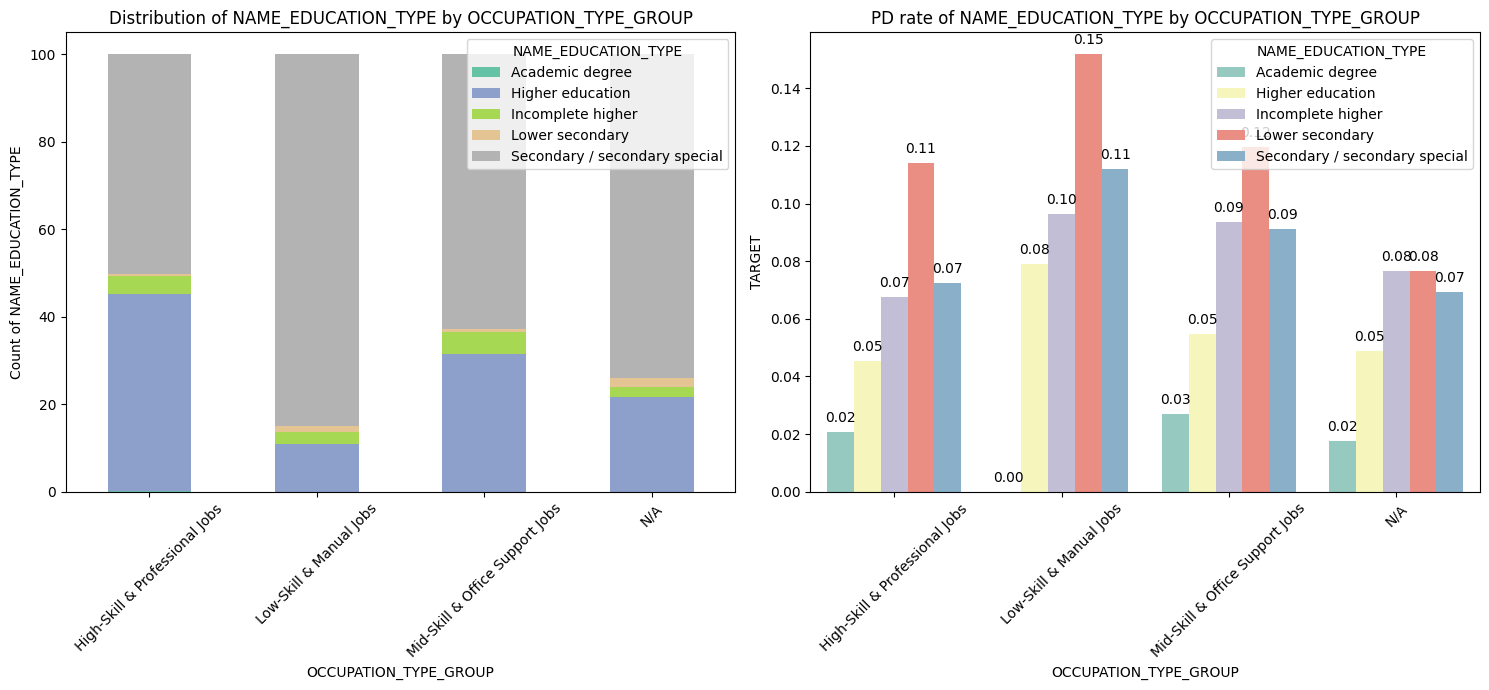

In [18]:

subset = ['OCCUPATION_TYPE_GROUP', 'NAME_EDUCATION_TYPE']
formula = 'Count'
xlabel_rotation = 45

#proportion
df_grouped = df_train.groupby(subset).size().reset_index(name=formula)
    
total_count_per_A = df_grouped.groupby(subset[0])[formula].transform('sum')
df_grouped['Proportion'] = 100*df_grouped[formula] / total_count_per_A

df_pivot_proportion = df_grouped.pivot_table(index=subset[0], columns=subset[1], values='Proportion', aggfunc='sum', fill_value=0)

#PD rate
pd_per_category = df_train.groupby(subset)['TARGET'].mean().reset_index()

#plot
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

#sns.barplot(x=subset[0], y='Proportion', hue=subset[1], data=df_grouped, palette='Set2', ax=axes[0])
ax0 = df_pivot_proportion.plot(kind='bar', stacked=True, ax=axes[0], cmap='Set2')

    
axes[0].set_title(f'Distribution of {subset[1]} by {subset[0]}')
axes[0].set_xlabel(subset[0])
axes[0].set_ylabel(f'{formula} of {subset[1]}')
axes[0].tick_params(axis='x', labelrotation=xlabel_rotation)

sns.barplot(x=subset[0], y='TARGET', hue=subset[1], data=pd_per_category, palette='Set3', ax=axes[1])

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}', 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     xytext=(0, 5), 
                     textcoords='offset points', 
                     ha='center', va='bottom')
    
axes[1].set_title(f'PD rate of {subset[1]} by {subset[0]}')
axes[1].set_xlabel(subset[0])
axes[1].tick_params(axis='x', labelrotation=xlabel_rotation)

plt.tight_layout()
plt.show()

In [19]:
def plot_subset_numerical(dataframe, subset, bins, xlabelrotation: int = 0, bw_adjust: float = 5.0):
   
    g = sns.displot(
        data=dataframe, 
        x=subset[1], 
        hue=subset[0], 
        kind='kde', 
        fill=False, 
        palette='Set2', 
        common_norm=False, 
        bw_adjust=bw_adjust,
        height=4, aspect=1.5  # Controls figure size
    )
    g.set_axis_labels(subset[1], "Density")
    g.fig.suptitle(f'{subset[1]} distribution by {subset[0]}', fontsize=12)
    plt.xticks(rotation=xlabelrotation)  # Rotate x-axis labels

    plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

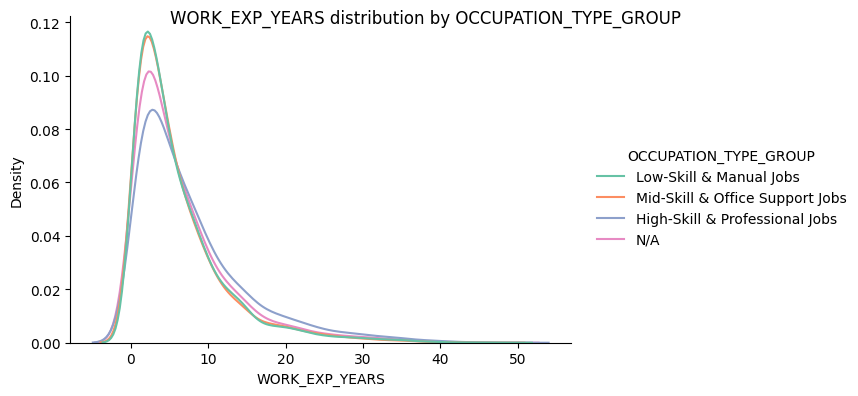

In [20]:
df_train['WORK_EXP_YEARS'] = df_train['DAYS_EMPLOYED'] * (-1) / 365
numerical_columns.append('WORK_EXP_YEARS')
subset = ['OCCUPATION_TYPE_GROUP', 'WORK_EXP_YEARS']
subset_2 = subset[1]
df_grouped = df_train[df_train[subset_2] > -1000][subset] #excluding outliers

plot_subset_numerical(df_grouped, subset, 50, 0, 2)

- The distribution of work experience by occupation shows that the lower the skill requirement, the shorter the work experience, indicating that customers in low-skill jobs tend to have unstable careers and frequently change jobs.
- For customers who completed only secondary education and work in low-skill jobs, there is a high likelihood of job instability and frequent job changes, which may lead to financial instability.

If the distribution of external scores from Model 2 and Model 3 shows no distinction across occupational groups, then only Model 1's external score differentiates them. Specifically, the High-Skill group has a higher score compared to others

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

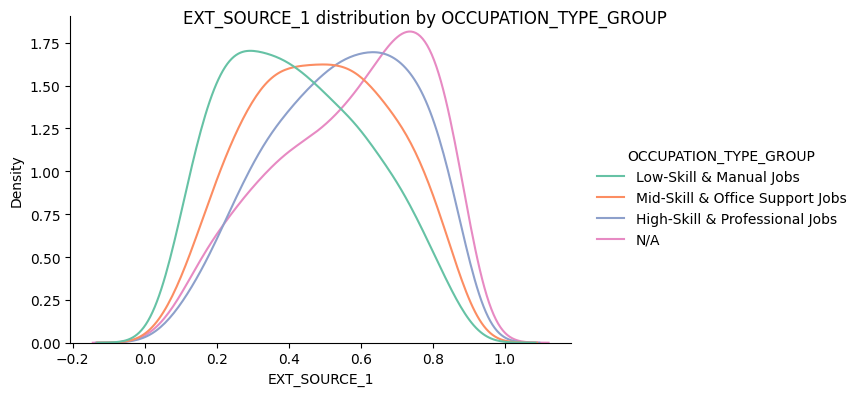

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

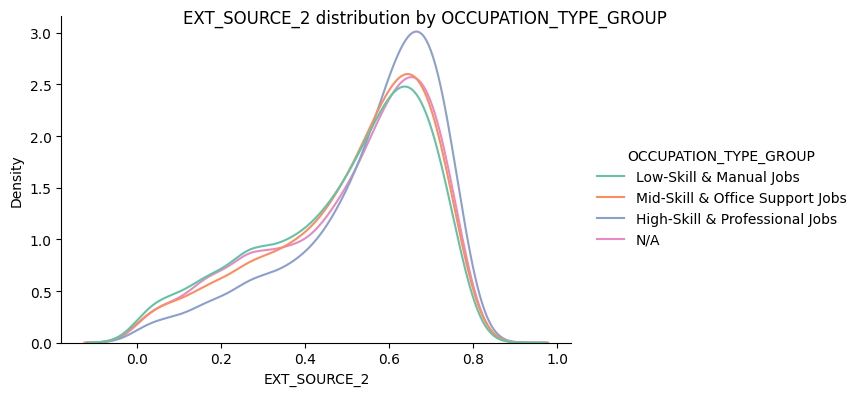

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

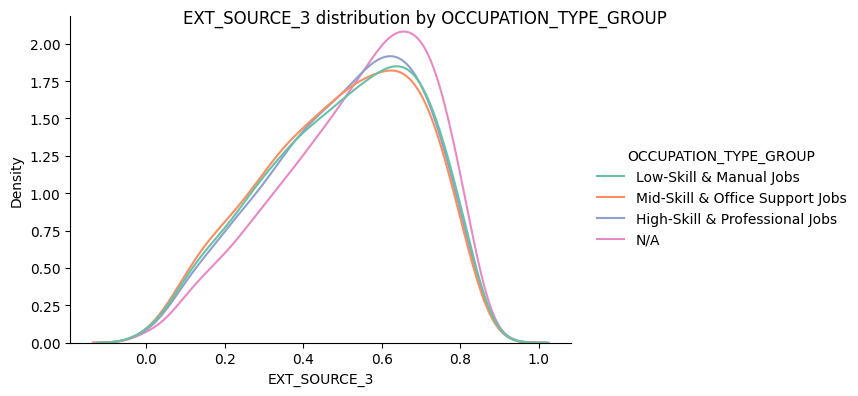

In [21]:
for i in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    subset = ['OCCUPATION_TYPE_GROUP', i]
    subset_2 = subset[1]
    df_grouped = df_train[subset]
    
    plot_subset_numerical(df_grouped, subset, 50, 0, 2)

Based on the income distribution for those earning less than 500,000, the High-Skill group has a higher income compared to the other two groups. This also means that the Low-Skill and Mid-Skill groups have lower incomes, which may impact their ability to repay debt.

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

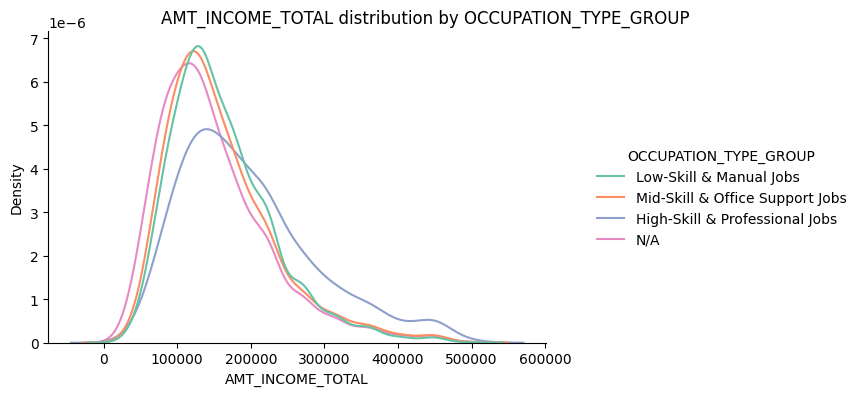

In [22]:
subset = ['OCCUPATION_TYPE_GROUP', 'AMT_INCOME_TOTAL']
subset_2 = subset[1]

df_grouped = df_train[(df_train[subset_2] < 500000)][subset]
plot_subset_numerical(df_grouped, subset, 50, 0, 2.25)

### 2.5.2 Bureau credit information

In [23]:
bureau_credit['PAID_MONTHS'] = ((bureau_credit['DAYS_CREDIT_ENDDATE'] - bureau_credit['DAYS_CREDIT'] - bureau_credit['CREDIT_DAY_OVERDUE'])/30).round()
bureau_credit['TENOR'] = ((bureau_credit['DAYS_CREDIT_ENDDATE'] - bureau_credit['DAYS_CREDIT'])/30).round()
bureau_credit['BUCKET'] = np.where(bureau_credit['AMT_CREDIT_MAX_OVERDUE'] == 0 , 'B0',
                          np.where(bureau_credit['AMT_CREDIT_MAX_OVERDUE'] < 30, 'B1', 
                          np.where(bureau_credit['AMT_CREDIT_MAX_OVERDUE'] < 60, 'B2',
                          np.where(bureau_credit['AMT_CREDIT_MAX_OVERDUE'] < 90, 'B3', 
                          'B4+'))))

bureau_credit['AMT_ANNUITY_2'] = np.where(bureau_credit['CREDIT_ACTIVE'] == 'Closed', 0, bureau_credit['AMT_ANNUITY'])

In [24]:
merged_df_train = df_train.merge(
    bureau_credit[['SK_ID_CURR', 'CREDIT_ACTIVE', 'PAID_MONTHS', 'TENOR', 'AMT_ANNUITY_2', 'BUCKET']], 
    on='SK_ID_CURR', 
    how='left'
)

merged_df_train['TOTAL_AMT_ANNUITY'] = merged_df_train['AMT_ANNUITY'] + merged_df_train['AMT_ANNUITY_2'] 
merged_df_train['DTI'] = (merged_df_train['AMT_ANNUITY_2']/merged_df_train['AMT_INCOME_TOTAL'] ) * 100
numerical_columns.append('DTI')

- Customers who simultaneously have active loans at other financial institutions have a PD rate that is 2%-3% higher compared to those who only have a loan with Home Credit.

- This suggests that borrowers with multiple active loans may face higher financial pressure, increasing their risk of default

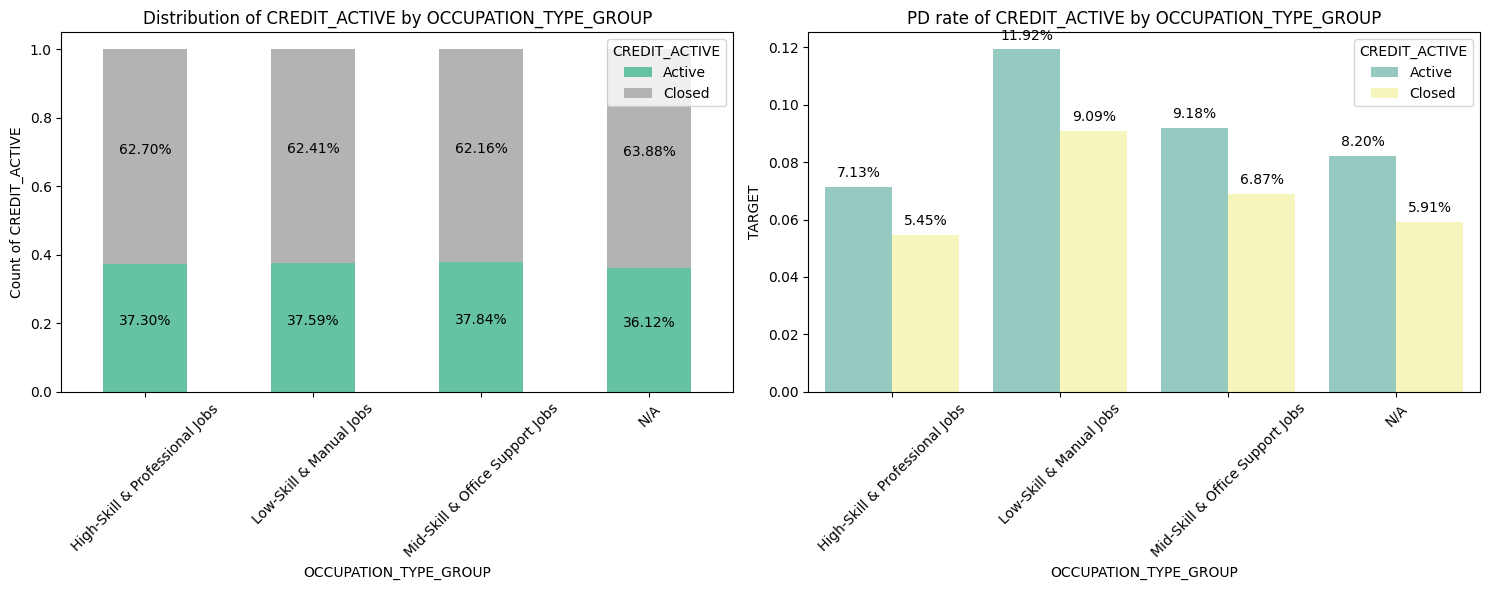

In [25]:

subset = ['OCCUPATION_TYPE_GROUP', 'CREDIT_ACTIVE']
formula = 'Count'
xlabel_rotation = 45

#proportion
df_grouped = merged_df_train[merged_df_train['CREDIT_ACTIVE'].isin(['Closed', 'Active'])].groupby(subset).size().reset_index(name=formula)
    
total_count_per_A = df_grouped.groupby(subset[0])[formula].transform('sum')
df_grouped['Proportion'] = df_grouped[formula] / total_count_per_A

df_pivot_proportion = df_grouped.pivot_table(index=subset[0], columns=subset[1], values='Proportion', aggfunc='sum', fill_value=0)

#PD rate
pd_per_category = merged_df_train[merged_df_train['CREDIT_ACTIVE'].isin(['Closed', 'Active'])].groupby(subset)['TARGET'].mean().reset_index()

#plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

#sns.barplot(x=subset[0], y='Proportion', hue=subset[1], data=df_grouped, palette='Set2', ax=axes[0])
ax0 = df_pivot_proportion.plot(kind='bar', stacked=True, ax=axes[0], cmap='Set2')

for p in ax0.patches:
    height = p.get_height()
    if height > 0: 
        ax0.annotate(f'{height:.2%}', 
                     (p.get_x() + p.get_width() / 2., p.get_y() + p.get_height() / 2.), 
                     xytext=(0, 5), 
                     textcoords='offset points', 
                     ha='center', va='center')
    
axes[0].set_title(f'Distribution of {subset[1]} by {subset[0]}')
axes[0].set_xlabel(subset[0])
axes[0].set_ylabel(f'{formula} of {subset[1]}')
axes[0].tick_params(axis='x', labelrotation=xlabel_rotation)

sns.barplot(x=subset[0], y='TARGET', hue=subset[1], data=pd_per_category, palette='Set3', ax=axes[1])

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2%}', 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     xytext=(0, 5), 
                     textcoords='offset points', 
                     ha='center', va='bottom')
    
axes[1].set_title(f'PD rate of {subset[1]} by {subset[0]}')
axes[1].set_xlabel(subset[0])
axes[1].tick_params(axis='x', labelrotation=xlabel_rotation)

plt.tight_layout()
plt.show()

- The total monthly repayment amount (including outstanding debt at Home Credit and other financial institutions) is categorized into three main DTI (Debt-to-Income) groups: DTI < 25%, DTI 25-50%, and DTI > 200%.
- The PD rate decreases as the DTI ratio decreases

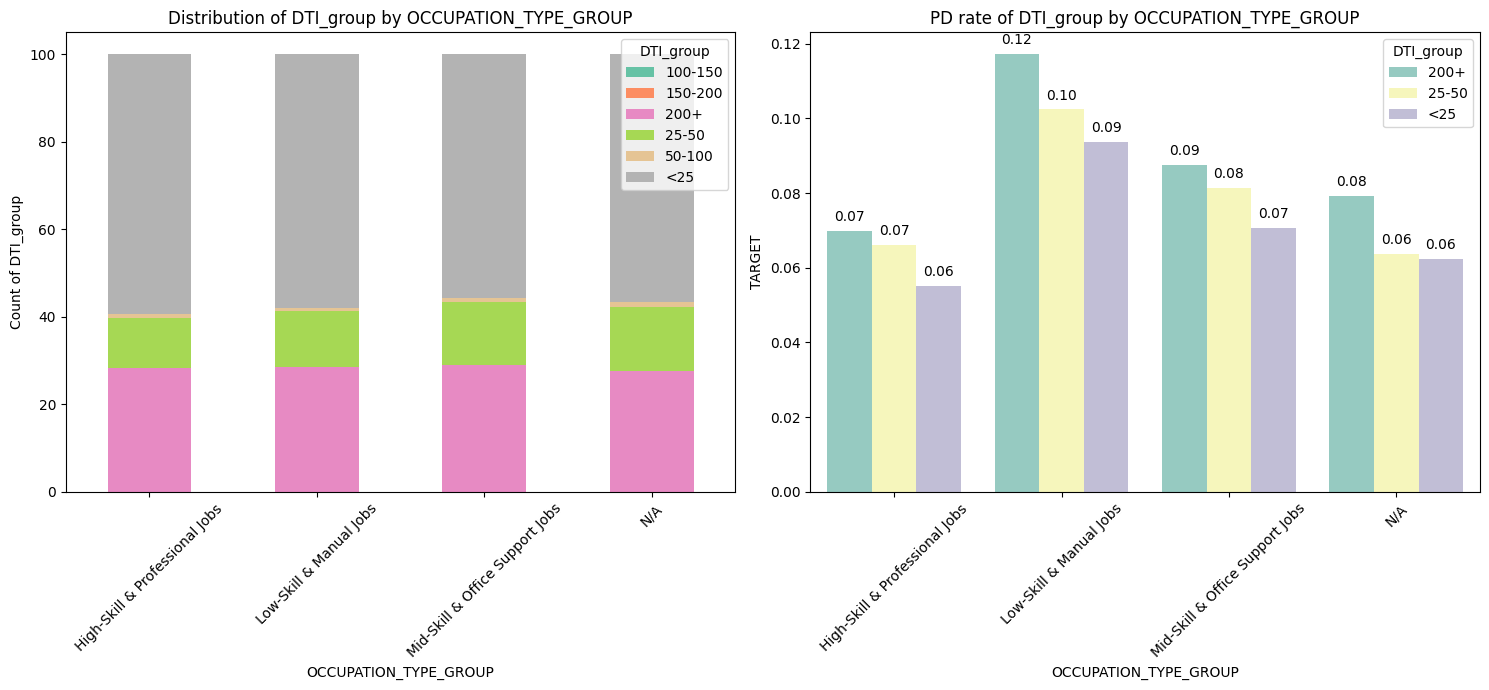

In [26]:
merged_df_train['DTI'] = (merged_df_train['TOTAL_AMT_ANNUITY']/merged_df_train['AMT_INCOME_TOTAL'] ) * 100
numerical_columns.append('DTI')

merged_df_train['DTI_group'] = np.where(
    merged_df_train['DTI'] < 25, '<25',
    np.where(merged_df_train['DTI'] < 50, '25-50',
    np.where(merged_df_train['DTI'] < 100, '50-100',
    np.where(merged_df_train['DTI'] < 150, '100-150',
    np.where(merged_df_train['DTI'] < 200, '150-200', '200+')))))

categorical_columns.append('DTI_group')

subset = ['OCCUPATION_TYPE_GROUP', 'DTI_group']
formula = 'Count'
xlabel_rotation = 45

#proportion
df_grouped = merged_df_train[merged_df_train['CREDIT_ACTIVE'].isin(['Closed', 'Active'])].groupby(subset).size().reset_index(name=formula)
    
total_count_per_A = df_grouped.groupby(subset[0])[formula].transform('sum')
df_grouped['Proportion'] = 100*df_grouped[formula] / total_count_per_A

df_pivot_proportion = df_grouped.pivot_table(index=subset[0], columns=subset[1], values='Proportion', aggfunc='sum', fill_value=0)

#PD rate
pd_per_category = merged_df_train[(merged_df_train['DTI_group'].isin(['<25', '25-50', '200+'])) & (merged_df_train['CREDIT_ACTIVE'].isin(['Active', 'Closed']))].groupby(subset)['TARGET'].mean().reset_index()

#plot
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

#sns.barplot(x=subset[0], y='Proportion', hue=subset[1], data=df_grouped, palette='Set2', ax=axes[0])
ax0 = df_pivot_proportion.plot(kind='bar', stacked=True, ax=axes[0], cmap='Set2')
    
axes[0].set_title(f'Distribution of {subset[1]} by {subset[0]}')
axes[0].set_xlabel(subset[0])
axes[0].set_ylabel(f'{formula} of {subset[1]}')
axes[0].tick_params(axis='x', labelrotation=xlabel_rotation)

sns.barplot(x=subset[0], y='TARGET', hue=subset[1], data=pd_per_category, palette='Set3', ax=axes[1])

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}', 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     xytext=(0, 5), 
                     textcoords='offset points', 
                     ha='center', va='bottom')
    
axes[1].set_title(f'PD rate of {subset[1]} by {subset[0]}')
axes[1].set_xlabel(subset[0])
axes[1].tick_params(axis='x', labelrotation=xlabel_rotation)

plt.tight_layout()
plt.show()

## 3. Conclusion and policy recommendation

## 3.1 Conclusion

[VIE] Tỷ lệ PD bị tác động bới nhiều tố, trong bài phân tích này chỉ ra các yếu tố tác động như dưới đây:
1. Younger Age, Higher Risk of Bad Debt
- Tuổi min là 25 tuổi, không vay học sinh sinh viên từ 18-25 tuổi
2. Lower Education Level, Higher PD Risk
  - Khách hàng có trình độ học vấn thấp hơn (ví dụ lower secondary hoặc secondary) cho thấy tỷ lệ PD cao hơn
3. Lower-Skill Jobs, Higher PD Rates
- Khách hàng làm việc tại công việc yêu cầu ít kĩ năng khả năng vỡ nợ cao hơn
- Phân tích sâu hơn về Lower-Skill Jobs: 
    * Tập trung phần lớn là khách hàng hoàn thành chương trình học thấp secondar/secondary special. 
    * Do công việc không đòi hỏi cao nên thu nhập của khách hàng này cũng thấp hơn do với các ngành nghề khác
    * Công việc không ổn định do số thánh kinh nghiệm làm việc ngắn, nên ảnh hưởng đến sự bất ổn định của thu nhập.
    * Phân phối điểm Score External model 1 tập trung dải điểm giảm dần từ kĩ năng công việc phức tạp, trung bình và đơn giản.
4. Khách hàng có nhiều khoản vay tính tại Home credit và tổ chức tín dụng khác làm tăng áp lực trả nợ và có tỷ lệ PD cao. Đối với khách hàng này, nghĩa vụ trả nợ trong 1 tháng trên thu nhập (DTI) khá cao, đạt 200% so với thu nhập và đều chiếm khoảng 30% danh mục giải ngân. Đặc biệt đối với khách hàng có thu nhập không ổn định sẽ khó hoàn thành nghĩa vụ trả nợ 

[ENG] The PD rate is influenced by multiple factors. This analysis highlights the key contributing factors as follows:
1. Younger Age, Higher Risk of Bad Debt
- The minimum borrowing age is 25, with no lending to students aged 18-25.
- Younger borrowers tend to have less stable income and financial experience.
2. Lower Education Level, Higher PD Risk
- Customers with lower education levels (e.g., Lower Secondary, Secondary Special) show a higher default risk.
3. Lower-Skill Jobs, Higher PD Rates
- Customers in low-skill occupations are more likely to default.
4. Detailed insights into Lower-Skill Jobs:
- Education: The majority have Secondary/Secondary Special education.
- Income: Due to lower job requirements, their income is lower than in other occupations.
- Job Stability: Short work experience suggests frequent job changes, leading to unstable income.
- External Score Distribution: Model 1 scores decrease gradually from high-skill to mid-skill to low-skill jobs.
  - Multiple Active Loans Increase Default Risk: Customers with multiple loans at Home Credit and other financial institutions face higher repayment pressure. Their Debt-to-Income (DTI) ratio often exceeds 200%, representing 30% of total disbursements. Borrowers with unstable income struggle to meet repayment obligations.

## 3.2 Policy recommendation

[VIE] Các chính sách điều tiết để quản trị danh mục thay đổi theo từng thời kì tuỳ thuộc vào khẩu vị rủi ro và chiến lược kinh doanh của công ty.

**Nới lỏng chínhh sách đối với KH rủi ro thấp**
1. Khách hàng rủi ro thấp bao gồm: 
- Khách hàng có công việc ổn định (thời gian công tác đủ lâu), thuộc nhóm ngành nghề có kỹ năng cao
- Khách hàng sinh sống tại khu vực có kinh tế ổn định và rank cao
- Khách hàng có điểm số tín dụng cao (External Score Model 1 )
2. Chính sách
- Áp dụng tăng hạn mức hoặc giảm lãi suất để thu hút khách hàng
- Áp dụng chính sách phê duyệt tự đông, phê duyệt trước để giảm thời gian thẩm định và tăng trải nghiệm khách hàng

**Thắt chặt chính sách đối với KH rủi ro cao**
1. Khách hàng trẻ tuổi (25-30):
    - Yêu cầu cung cấp giấy giờ xác minh thu nhập (hợp đồng lao động,..) hoặc một số thông tin nội suy thu nhập như: số tiền giao dịch trung bình, số dư tài khoản hoặc tiền gửi tiết kiệm trên tài khoản ngân hàng, ví điện từ
    - Giới hạn hạn mức vay hoặc yêu cầu khoản trả trước cao hơn
2. Khách hàng có trình độ học vấn thấp (Lower Secondary/ Secondary Special)
    - Giảm dần tỷ trọng giải ngân của nhóm này trên toàn danh mục (hiện tại tỷ trọng chiếm từ 50%-70% tuỳ ngành nghề)
    - Không cho vay với nhóm khách hàng có điểm mô hình thấp
    - Giảm hạn mức vay hoặc yêu cầu khoản trả trước cao hơn
3. Khách hàng làm việc trong nhóm ngành lao động phổ thông có thu nhập không ổn định
    - Giảm hạn mức vay đối với kinh nghiệm làm việc  có số tháng dưới ngưỡng mục tiêu, khách hàng có nghề nghiệp thuộc nhóm Low-skill bao gồm: 
4. Khách hàng có nhiều khoản vay cùng lúc & DTI cao
    - Áp dụng ngưỡng DTI chặt chẽ hơn đối với khách hàng có nhiều khoản vay tại các tổ chức tín dụng khác.
    - Xây dựng cảnh báo sớm cho khách hàng có nhiều khoản vay chưa thanh toán tại mỗi thời điểm.

Đối với các chính sách thắt chặt, theo quan điểm liên quan đến cho vay tài chính tiêu dùng nói về việc cung cấp giải pháp hỗ trợ tài chính nhanh chóng, tiện lợi cho từng cá nhân. Hạn chế các trường cắt giảm khách hàng mạnh, thay vào đó xây dựng khung quản lý hạn mức đảm bảo phù hợp đối với khả năng trả nợ của từng cá nhân:
- Xây dựng hạn mức theo từng phân khúc khách hàng theo điểm tín dụng 
- Theo hành vi chi tiêu về hành vi trả nợ của khách hàng
- Tăng hạn mức cho khách hàng có điểm tín dụng cải thiện theo thời gian
- Xây dựng bộ chí số cảnh báo sớm để thực hiện thu hồi nợ sớm hoặc cắt giảm hạn mức chưa sử dụng

[ENG] Regulatory policies for portfolio management change over time depending on the company’s risk appetite and business strategy.

**Lossening policies for low-risk customers**

1. Low-risk customers include:
- Customers with stable jobs (long enough employment duration), belonging to industries requiring high skills.
- Customers living in economically stable and high-ranking areas.
- Customers with high credit scores (External Score Model 1).
2. Policies:
- Apply increased loan limits or reduced interest rates to attract customers.
- Implement auto-approval or pre-approval policies to reduce evaluation time and enhance the customer experience.

**Tightening policies for high-risk customers**

1. Young customers (25-30 years old):
- Require income verification documents (e.g., employment contract) or some inferred income information such as: average transaction amount, account balance, or savings on a bank account, e-wallet.
- Limit loan amounts or require higher down payments.
2. Customers with low educational qualifications (Lower Secondary/Secondary Special):
- Gradually reduce the proportion of disbursements from this group in the overall portfolio (currently, the proportion ranges from 50%-70% depending on the industry).
- Do not lend to customers with low model scores.
- Reduce loan limits or require higher down payments.
3. Customers working in labor-intensive industries with unstable income:
- Reduce loan limits for those with work experience below the target threshold. Customers with low-skill occupations are included in this group.
4. Customers with multiple loans & high DTI (Debt-to-Income ratio):
- Apply stricter DTI thresholds for customers with loans from multiple other financial institutions.
- Set up early warning alerts for customers with multiple outstanding loans at any given time.

For tightening policies, from a perspective related to consumer finance lending, the focus is on providing fast and convenient financial support solutions to individuals. It is important to avoid overly harsh cuts for customers, and instead, establish a framework for managing loan limits that aligns with the repayment capacity of each individual:

- Set loan limits based on customer segments according to credit scores.
- Based on customer spending behavior and repayment patterns.
- Increase loan limits for customers whose credit scores improve over time.
- Create an early warning system to initiate early debt collection or reduce unused credit limits.
